# Dashboard trực quan — Valorant Data Mining

Notebook này **không chạy lại mô hình**. Nó đọc các tập dữ liệu đã làm sạch và các bảng kết quả trong `data/processed/` và `outputs/tables/` để trình bày dễ xem hơn.

Trước khi chạy notebook, hãy chạy pipeline một lần tại thư mục dự án:

```bash
make all
```

Sau đó trong Jupyter, chọn **Run All**. Với các phần theo map, chỉ cần đổi giá trị biến `SELECTED_MAP`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 100)

# Notebook nằm trong notebooks/, nên thư mục dự án là thư mục cha.
ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "outputs" / "tables"

print(f"Đang đọc dữ liệu từ: {ROOT}")
assert PROCESSED.exists(), "Không tìm thấy data/processed. Hãy mở notebook từ thư mục dự án."
assert TABLES.exists(), "Không tìm thấy outputs/tables. Hãy chạy `make all` trước."


Đang đọc dữ liệu từ: /Users/minhduc/work/valorant-mining


In [2]:
# Các dữ liệu đã làm sạch và kết quả khai phá
players = pd.read_csv(TABLES / "player_clusters.csv")
compositions = pd.read_csv(PROCESSED / "team_compositions.csv")
rules = pd.read_csv(TABLES / "agent_rules_by_map.csv")
pick_rates = pd.read_csv(TABLES / "agent_pick_rates_by_map.csv")
exact_comps = pd.read_csv(TABLES / "exact_compositions.csv")
cluster_profiles = pd.read_csv(TABLES / "cluster_profiles_raw.csv")
cluster_eval = pd.read_csv(TABLES / "cluster_evaluation.csv")

print(f"Người chơi đã phân cụm: {len(players):,}")
print(f"Đội hình Agent: {len(compositions):,}")
print(f"Luật kết hợp: {len(rules):,}")
print(f"Map: {', '.join(sorted(compositions['Map'].unique()))}")


Người chơi đã phân cụm: 2,599
Đội hình Agent: 28,010
Luật kết hợp: 580
Map: Ascent, Bind, Breeze, Fracture, Haven, Icebox, Split


## 1. Tổng quan dữ liệu

,Chỉ số,Giá trị
0,Số game sau làm sạch,"14,005"
1,Số đội hình Agent,"28,010"
2,Đội hình có nhãn thắng/thua,"27,382"
3,Người chơi phân cụm,"2,599"
4,Số map,7


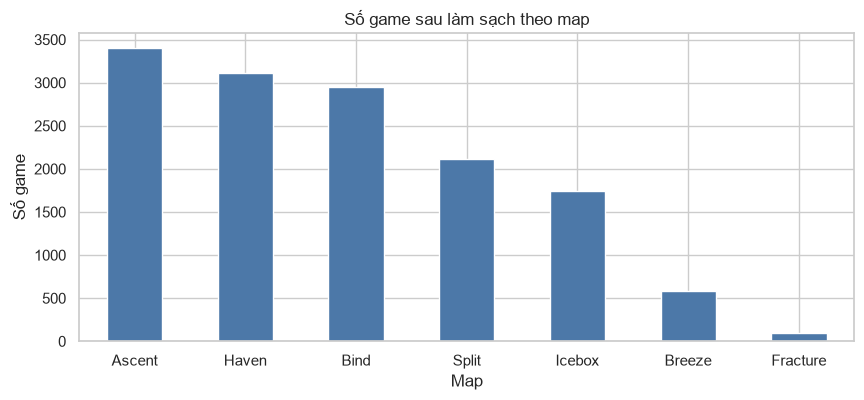

In [3]:
n_games = compositions["GameID"].nunique()
n_labeled = compositions["won"].notna().sum()
n_maps = compositions["Map"].nunique()

summary = pd.DataFrame({
    "Chỉ số": ["Số game sau làm sạch", "Số đội hình Agent", "Đội hình có nhãn thắng/thua", "Người chơi phân cụm", "Số map"],
    "Giá trị": [f"{n_games:,}", f"{len(compositions):,}", f"{n_labeled:,}", f"{len(players):,}", n_maps],
})
display(summary)

map_counts = (compositions.groupby("Map")["GameID"].nunique()
              .sort_values(ascending=False)
              .rename("Số game"))
ax = map_counts.plot.bar(figsize=(10, 4), color="#4C78A8")
ax.set_title("Số game sau làm sạch theo map")
ax.set_xlabel("Map")
ax.set_ylabel("Số game")
plt.xticks(rotation=0)
plt.show()


## 2. Phân cụm người chơi

In [4]:
cluster_summary = (players.groupby(["cluster", "cluster_label"], as_index=False)
                   .agg(
                       players=("PlayerID", "nunique"),
                       win_rate=("win_rate", "mean"),
                       acs=("acs", "mean"),
                       adr=("adr", "mean"),
                       kd=("kd", "mean"),
                       deaths_pr=("deaths_pr", "mean"),
                       assists_pr=("assists_pr", "mean"),
                   )
                   .sort_values("cluster"))

for col in ["win_rate"]:
    cluster_summary[col] = cluster_summary[col].map(lambda x: f"{x:.1%}")
for col in ["acs", "adr", "kd", "deaths_pr", "assists_pr"]:
    cluster_summary[col] = cluster_summary[col].map(lambda x: f"{x:.3f}" if col != "acs" and col != "adr" else f"{x:.1f}")

display(cluster_summary.rename(columns={
    "cluster": "Cụm", "cluster_label": "Tên cụm", "players": "Số người chơi",
    "win_rate": "Win rate", "acs": "ACS", "adr": "ADR", "kd": "K/D",
    "deaths_pr": "Deaths/round", "assists_pr": "Assists/round"
}))


,Cụm,Tên cụm,Số người chơi,Win rate,ACS,ADR,K/D,Deaths/round,Assists/round
0,0,Mở giao tranh · Sát thương cao,760,48.6%,228.3,144.9,1.090,0.731,0.214
1,1,Chết nhiều · Hiệu quả thấp,849,37.6%,175.7,115.1,0.822,0.736,0.255
2,2,Ít chết · Hiệu quả cao,990,52.6%,200.9,131.2,1.030,0.684,0.278


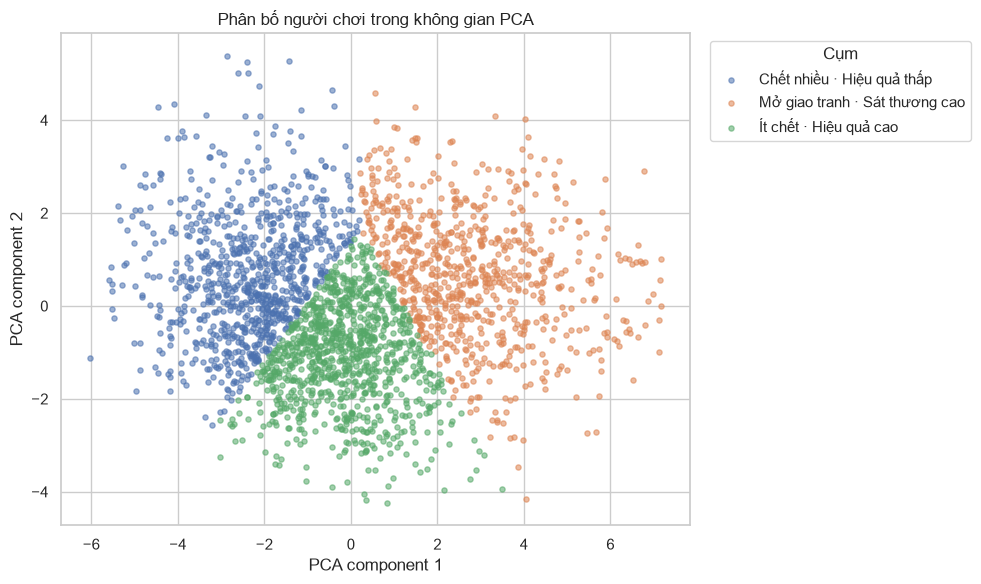

In [5]:
# Biểu đồ PCA: mỗi chấm là một người chơi; màu là cụm K-Means.
fig, ax = plt.subplots(figsize=(10, 6))
for label, group in players.groupby("cluster_label"):
    ax.scatter(group["pca1"], group["pca2"], s=14, alpha=0.55, label=label)
ax.set_title("Phân bố người chơi trong không gian PCA")
ax.set_xlabel("PCA component 1")
ax.set_ylabel("PCA component 2")
ax.legend(title="Cụm", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


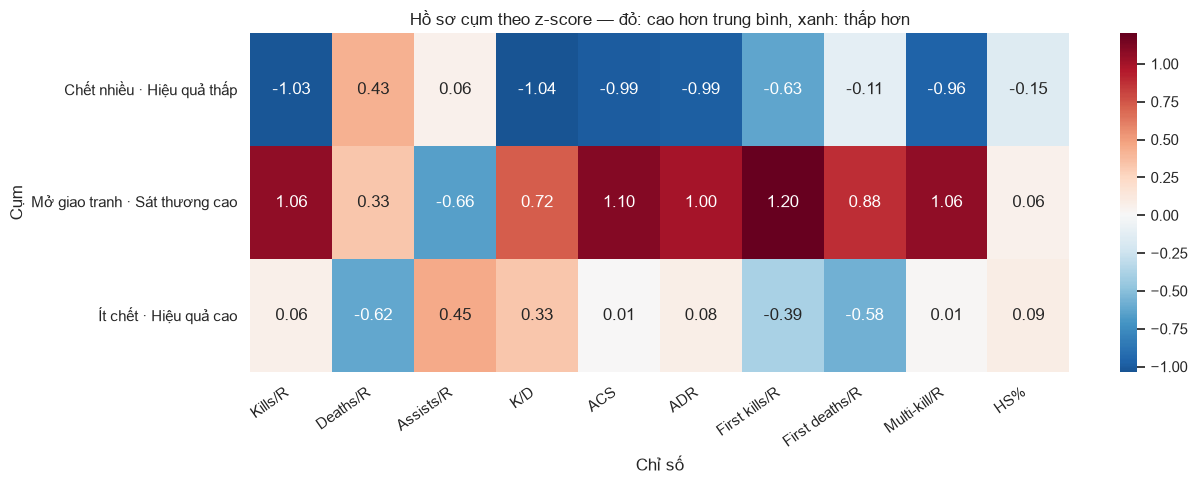

In [6]:
# So sánh các chỉ số chính giữa các cụm.
metric_cols = ["kills_pr", "deaths_pr", "assists_pr", "kd", "acs", "adr", "fk_pr", "fd_pr", "multi_pr", "hs"]
metric_labels = {
    "kills_pr": "Kills/R", "deaths_pr": "Deaths/R", "assists_pr": "Assists/R", "kd": "K/D",
    "acs": "ACS", "adr": "ADR", "fk_pr": "First kills/R", "fd_pr": "First deaths/R",
    "multi_pr": "Multi-kill/R", "hs": "HS%"
}

# Chuẩn hóa theo z-score để đặt các chỉ số khác đơn vị lên cùng một biểu đồ.
profile = players.groupby("cluster_label")[metric_cols].mean()
z_profile = (profile - players[metric_cols].mean()) / players[metric_cols].std()
z_profile = z_profile.rename(columns=metric_labels)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(z_profile, annot=True, fmt=".2f", center=0, cmap="RdBu_r", ax=ax)
ax.set_title("Hồ sơ cụm theo z-score — đỏ: cao hơn trung bình, xanh: thấp hơn")
ax.set_xlabel("Chỉ số")
ax.set_ylabel("Cụm")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 3. Agent theo map và luật kết hợp

In [7]:
# Đổi map tại đây để xem phần phân tích chi tiết.
SELECTED_MAP = "Icebox"
assert SELECTED_MAP in set(compositions["Map"]), f"Map không hợp lệ: {SELECTED_MAP}"
print(f"Map đang xem: {SELECTED_MAP}")


Map đang xem: Icebox


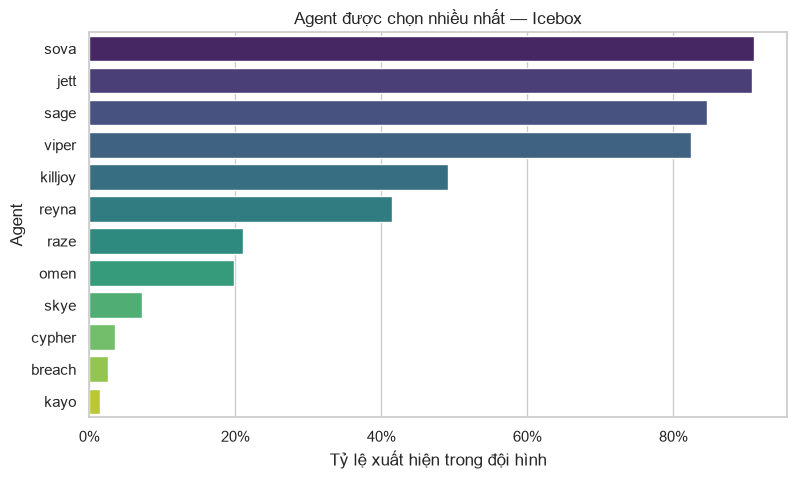

,Agent,Lượt chọn,Số đội hình,Tỷ lệ chọn
85,sova,3179,3494,91.0%
86,jett,3170,3494,90.7%
87,sage,2955,3494,84.6%
88,viper,2879,3494,82.4%
89,killjoy,1717,3494,49.1%
90,reyna,1446,3494,41.4%
91,raze,737,3494,21.1%
92,omen,690,3494,19.7%
93,skye,254,3494,7.3%
94,cypher,124,3494,3.5%


In [8]:
map_picks = (pick_rates[pick_rates["map"] == SELECTED_MAP]
             .sort_values("pick_rate", ascending=False)
             .head(12)
             .copy())

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=map_picks, x="pick_rate", y="agent", hue="agent", legend=False, palette="viridis", ax=ax)
ax.set_title(f"Agent được chọn nhiều nhất — {SELECTED_MAP}")
ax.set_xlabel("Tỷ lệ xuất hiện trong đội hình")
ax.set_ylabel("Agent")
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
plt.show()

display(map_picks[["agent", "picks", "teams", "pick_rate"]].assign(
    pick_rate=lambda df: df["pick_rate"].map("{:.1%}".format)
).rename(columns={"agent": "Agent", "picks": "Lượt chọn", "teams": "Số đội hình", "pick_rate": "Tỷ lệ chọn"}))


In [9]:
# Các luật có lift cao nhất trên map được chọn.
map_rules = (rules[rules["map"] == SELECTED_MAP]
             .sort_values(["lift", "support_count"], ascending=[False, False])
             .head(15)
             .copy())

show_rules = map_rules[["rule", "support_count", "support", "confidence", "lift", "win_rate_with_antecedent", "fisher_q_bh"]]
for col in ["support", "confidence", "win_rate_with_antecedent"]:
    show_rules[col] = show_rules[col].map("{:.1%}".format)
show_rules["lift"] = show_rules["lift"].map("{:.2f}".format)
show_rules["fisher_q_bh"] = show_rules["fisher_q_bh"].map("{:.3f}".format)

display(show_rules.rename(columns={
    "rule": "Luật Agent", "support_count": "Số đội hình", "support": "Support",
    "confidence": "Confidence", "lift": "Lift", "win_rate_with_antecedent": "Win rate khi có vế trái",
    "fisher_q_bh": "q-value (BH)"
}))


,Luật Agent,Số đội hình,Support,Confidence,Lift,Win rate khi có vế trái,q-value (BH)
454,"killjoy, raze → omen",129,3.7%,48.0%,2.43,54.3%,0.500
455,omen → raze,280,8.0%,40.6%,1.92,47.7%,0.526
456,omen → killjoy,372,10.6%,53.9%,1.10,47.7%,0.526
457,"reyna, sage → viper",1011,28.9%,89.2%,1.08,46.3%,0.082
458,"jett, omen → killjoy",293,8.4%,53.2%,1.08,46.6%,0.444
459,"reyna → sova, viper",1181,33.8%,81.7%,1.07,47.1%,0.090
460,"sova, viper → reyna",1181,33.8%,44.1%,1.07,50.2%,0.863
461,"sage, skye → viper",156,4.5%,87.6%,1.06,43.8%,0.455
462,"reyna, sova → viper",1181,33.8%,87.6%,1.06,47.7%,0.308
463,"viper → reyna, sova",1181,33.8%,41.0%,1.06,50.2%,0.839


**Cách đọc luật:** `A, B → C` có nghĩa là khi đội đã chọn A và B thì C thường cũng xuất hiện. Lift lớn hơn 1 cho thấy tổ hợp xuất hiện nhiều hơn kỳ vọng nếu các Agent độc lập. Đây là **đồng xuất hiện**, không phải quan hệ nguyên nhân-kết quả.

## 4. Đội hình Agent và tỷ lệ thắng

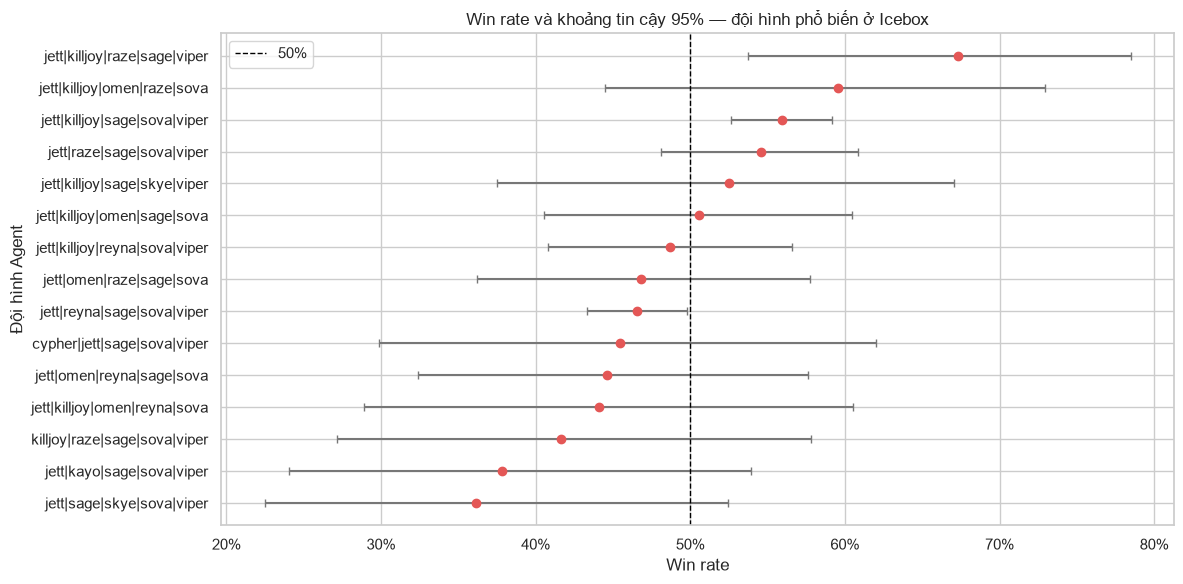

In [10]:
# Các đội hình phổ biến nhất trên map được chọn.
map_comps = (exact_comps[exact_comps["map"] == SELECTED_MAP]
             .sort_values("n", ascending=False)
             .head(15)
             .copy())

fig, ax = plt.subplots(figsize=(12, 6))
plot_data = map_comps.sort_values("win_rate")
ax.errorbar(
    plot_data["win_rate"], plot_data["agents_str"],
    xerr=[plot_data["win_rate"] - plot_data["win_rate_ci_low"],
          plot_data["win_rate_ci_high"] - plot_data["win_rate"]],
    fmt="o", color="#E45756", ecolor="#777777", capsize=3,
)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="50%")
ax.set_title(f"Win rate và khoảng tin cậy 95% — đội hình phổ biến ở {SELECTED_MAP}")
ax.set_xlabel("Win rate")
ax.set_ylabel("Đội hình Agent")
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend()
plt.tight_layout()
plt.show()


In [11]:
show_comps = map_comps[["agents_str", "n", "wins", "win_rate", "win_rate_ci_low", "win_rate_ci_high", "fisher_q_bh", "significant_fdr"]].copy()
for col in ["win_rate", "win_rate_ci_low", "win_rate_ci_high"]:
    show_comps[col] = show_comps[col].map("{:.1%}".format)
show_comps["fisher_q_bh"] = show_comps["fisher_q_bh"].map("{:.3f}".format)

display(show_comps.rename(columns={
    "agents_str": "Đội hình", "n": "Số lần xuất hiện", "wins": "Số trận thắng",
    "win_rate": "Win rate", "win_rate_ci_low": "CI thấp", "win_rate_ci_high": "CI cao",
    "fisher_q_bh": "q-value (BH)", "significant_fdr": "Có ý nghĩa sau FDR"
}))


,Đội hình,Số lần xuất hiện,Số trận thắng,Win rate,CI thấp,CI cao,q-value (BH),Có ý nghĩa sau FDR
339,jett|reyna|sage|sova|viper,896,417.0,46.5%,43.3%,49.8%,0.510,False
340,jett|killjoy|sage|sova|viper,883,494.0,55.9%,52.7%,59.2%,0.024,True
341,jett|raze|sage|sova|viper,231,126.0,54.5%,48.1%,60.8%,0.917,False
342,jett|killjoy|reyna|sova|viper,150,73.0,48.7%,40.8%,56.6%,1.000,False
343,jett|killjoy|omen|sage|sova,93,47.0,50.5%,40.6%,60.5%,1.000,False
344,jett|omen|raze|sage|sova,79,37.0,46.8%,36.2%,57.7%,1.000,False
345,jett|omen|reyna|sage|sova,56,25.0,44.6%,32.4%,57.6%,1.000,False
346,jett|killjoy|raze|sage|viper,52,35.0,67.3%,53.8%,78.5%,0.510,False
347,jett|killjoy|omen|raze|sova,42,25.0,59.5%,44.5%,73.0%,0.990,False
348,jett|killjoy|sage|skye|viper,40,21.0,52.5%,37.5%,67.1%,1.000,False


## 5. Lưu ý khi diễn giải

- Các kết quả phản ánh dữ liệu Valorant chuyên nghiệp từ 2020 đến đầu 2022, không phải meta hiện tại.
- Phân cụm mô tả nhóm hiệu suất trong dữ liệu; không khẳng định đây là vai trò chính thức của người chơi.
- Luật kết hợp mô tả Agent đi cùng nhau; lift cao không chứng minh đội hình đó mạnh hơn.
- Win rate quan sát có thể chịu ảnh hưởng bởi sức mạnh đội tuyển, đối thủ, giải đấu và patch.